# SmokeViz: data preparation

Builds the train / val / test dataset for smoke-density segmentation from the SmokeViz sample on Zenodo, completed with masks and tiles from the full SmokeViz on NOAA S3. Run top to bottom on Colab (no GPU needed). The output is `splits.csv`, used by the training notebooks.

### Starting point: the Zenodo sample
- "Sample Dataset of Smoke in GOES Imagery" ([zenodo.org/records/10946629](https://zenodo.org/records/10946629)): 1198 tiles of 256×256 px from 2020–2023, with images (`data/`) and lat/lon (`coords/`), **but no pixel masks**: only a tile-level label given by the folder (`None` / `Light` / `Medium` / `Heavy`).
- Splits in `subsample.pkl`: train = 2020, 2021, 2023 (1000 tiles); val / test = 2022 (99 + 99).

### What we found
- The full SmokeViz on S3 (`s3://noaa-gsl-experimental-pds/SmokeViz/`) has `data/` and `truth/` with the same `year/folder/name.tif` paths, so masks can be matched by name. They were found for **546 of the 618 smoke tiles** (sections 1 and 5).
- The **72 missing ones are all from 2022**: the image is not on S3 either, so the 2022 tiles were regenerated on S3. At least one 2022 image also changed under the same name. As a result val / test kept only 38 smoke tiles, **with no Heavy tile in val** (section 2).
- Masks are `(256, 256, 3)` binary and cumulative: channel 0 = Heavy, 1 = at least Medium, 2 = at least Light. Per-pixel label = `mask.sum(-1)` (0 none, 1 light, 2 medium, 3 heavy). The folder name is not the maximum density in the tile, e.g. 44% of `Medium` tiles also contain Heavy pixels (section 3).

### What we changed
- **Train: unchanged.** All 508 training smoke images are identical to the S3 version, so every mask matches its image (section 7).
- **Val / test: rebuilt from 2022 on S3** (section 6). 150 smoke tiles per split (60 Light, 50 Medium, 40 Heavy; at most one tile per satellite image; seed 42), plus the 2022 `None` tiles of the Zenodo sample, since S3 has no smoke-free tiles. Val and test are alternating 10-day blocks of 2022 (even blocks → val, odd → test), so they share no day. Heavy is over-represented on purpose, to get reliable per-class metrics.

### Final dataset

| Split | None | Light | Medium | Heavy | Total | Source |
|---|---|---|---|---|---|---|
| train | 492 | 319 | 120 | 69 | 1000 | Zenodo (2020, 2021, 2023) |
| val | 51 | 60 | 50 | 40 | 201 | smoke: S3 2022 · None: Zenodo 2022 |
| test | 37 | 60 | 50 | 40 | 187 | smoke: S3 2022 · None: Zenodo 2022 |

`splits.csv` has one row per tile with `split, source, root, year, folder, name`: the image is `root/data/year/folder/name`, the mask `root/truth/year/folder/name` (all zeros for `None` tiles). Read it with `pd.read_csv(path, dtype=str, keep_default_na=False)`, otherwise pandas turns the `None` folder into NaN.

## 0. Setup

In [1]:
!pip -q install tifffile boto3

import os
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/ADSP"
ZIP_DATA = f"{DRIVE_DIR}/sample_dataset.zip"     # Zenodo sample (images + coords)
ZIP_TRUTH = f"{DRIVE_DIR}/truth_sample.zip"      # masks from S3 (created by section 1)
LOCAL = "/content/smokeviz"
ZENODO_URL = "https://zenodo.org/records/10946629/files/sample_dataset.zip?download=1"
ZIP_MD5 = "9460bad737f5b6de1a9f4e0ace3d4ce3"

# Download once to Drive (if slow, aria2c -x 16 -s 16 is much faster than wget)
os.makedirs(DRIVE_DIR, exist_ok=True)
if not os.path.exists(ZIP_DATA):
    !wget -q --show-progress -O "{ZIP_DATA}" "{ZENODO_URL}"
md5 = !md5sum "{ZIP_DATA}"
assert md5[0].split()[0] == ZIP_MD5, "Corrupted zip: delete it from Drive and re-run this cell"

# Unzip to the local disk at every session (reading from Drive is slow)
!unzip -q -o "{ZIP_DATA}" -d "{LOCAL}"
if os.path.exists(ZIP_TRUTH):
    !unzip -q -o "{ZIP_TRUTH}" -d "{LOCAL}/sample_data"

Mounted at /content/drive


In [2]:
import collections
import pickle
import random
import re
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import boto3
import botocore
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from botocore import UNSIGNED
from botocore.config import Config

ROOT = Path("/content/smokeviz/sample_data")
FOLDERS = ["None", "Light", "Medium", "Heavy"]   # tile-level label (folder name)
LABELS = ["none", "light", "medium", "heavy"]    # per-pixel label = mask.sum(-1)
BUCKET, S3_PREFIX = "noaa-gsl-experimental-pds", "SmokeViz"

## 1. Pixel masks from S3

The full SmokeViz is in a public NOAA S3 bucket, with `data/` (images) and `truth/` (masks) sharing the same `year/folder/name.tif` paths. For each smoke tile of the sample we download only the matching mask. `None` tiles have no mask on S3: their mask is all zeros. Masks already on disk are skipped, and the first run saves a backup zip to Drive.

In [3]:
s3 = boto3.client("s3", config=Config(signature_version=UNSIGNED, max_pool_connections=32))


def s3_exists(key):
    try:
        s3.head_object(Bucket=BUCKET, Key=key)
        return True
    except botocore.exceptions.ClientError:
        return False


def fetch_mask(p):
    year, folder, name = p.parts[-3:]
    out = ROOT / "truth" / year / folder / name
    if out.exists():
        return "ok"
    out.parent.mkdir(parents=True, exist_ok=True)
    try:
        s3.download_file(BUCKET, f"{S3_PREFIX}/truth/{year}/{folder}/{name}", str(out))
        return "ok"
    except botocore.exceptions.ClientError:
        return "missing"


smoke_tiles = sorted(p for p in (ROOT / "data").rglob("*.tif") if p.parent.name != "None")
with ThreadPoolExecutor(32) as ex:
    status = list(ex.map(fetch_mask, smoke_tiles))
print(f"{len(smoke_tiles)} smoke tiles -> {status.count('ok')} masks, {status.count('missing')} missing on S3")

if not os.path.exists(ZIP_TRUTH):
    !cd "{ROOT}" && zip -qr "{ZIP_TRUTH}" truth

618 smoke tiles -> 546 masks, 72 missing on S3


## 2. Starting point: the Zenodo sample

Tiles per split and year as given by `subsample.pkl`, and how many of them can be used for segmentation after section 1.

In [4]:
meta = pickle.load(open(ROOT / "subsample.pkl", "rb"))
split_of = {Path(p).parts[-3:]: split for split, d in meta.items() for p in d["data"]}

rows = []
for p in sorted((ROOT / "data").rglob("*.tif")):
    year, folder, name = p.parts[-3:]
    if folder == "None":
        mask = "empty (None)"
    elif (ROOT / "truth" / year / folder / name).exists():
        mask = "from S3"
    else:
        mask = "missing on S3"
    rows.append({"year": year, "folder": folder, "name": name,
                 "split": split_of.get((year, folder, name), "not in pkl"), "mask": mask})
tiles = pd.DataFrame(rows)

# Logical order in the tables (not alphabetical)
tiles["split"] = pd.Categorical(tiles.split, ["train", "val", "test", "not in pkl"]).remove_unused_categories()
tiles["folder"] = pd.Categorical(tiles.folder, FOLDERS)

# Table 1: tiles per split and year
years = pd.crosstab(tiles.split, tiles.year, margins=True, margins_name="Total")
years.index.name, years.columns.name = "Split", "Year"
display(years.style.set_caption("Number of tiles per split and year"))

# Table 2: usable tiles (mask available or empty) / total tiles, per split and folder
usable = tiles["mask"] != "missing on S3"
total = pd.crosstab(tiles.split, tiles.folder, margins=True, margins_name="Total")
ok = (pd.crosstab(tiles.split[usable], tiles.folder[usable], margins=True, margins_name="Total")
      .reindex_like(total).fillna(0).astype(int))
summary = ok.astype(str) + " / " + total.astype(str)
summary["Missing masks"] = total["Total"] - ok["Total"]
summary.index.name, summary.columns.name = "Split", "Folder"
display(summary.style.set_caption("Usable tiles / total tiles (None tiles use an all-zero mask)"))

Year,2020,2021,2022,2023,Total
Split,,,,,
train,536,278,0,186,1000
val,0,0,99,0,99
test,0,0,99,0,99
Total,536,278,198,186,1198


Folder,None,Light,Medium,Heavy,Total,Missing masks
Split,,,,,,
train,492 / 492,319 / 319,120 / 120,69 / 69,1000 / 1000,0
val,51 / 51,14 / 27,7 / 15,0 / 6,72 / 99,27
test,37 / 37,6 / 31,7 / 20,4 / 11,54 / 99,45
Total,580 / 580,339 / 377,134 / 155,73 / 86,1126 / 1198,72


## 3. Mask format and label distribution

In [5]:
truth_files = sorted((ROOT / "truth").rglob("*.tif"))
m = tifffile.imread(truth_files[0])
print(f"{len(truth_files)} masks | shape {m.shape} | dtype {m.dtype} | values {np.unique(m)}")

M = np.stack([tifffile.imread(f) for f in truth_files]).astype(bool)   # (N, 256, 256, 3)
folder = np.array([f.parent.name for f in truth_files])

# Share of tiles with at least one pixel in each channel, by folder
display(pd.DataFrame({c: M[folder == c].any(axis=(1, 2)).mean(axis=0) for c in FOLDERS[1:]},
                     index=["ch0 (heavy)", "ch1 (>= medium)", "ch2 (>= light)"]).T.round(2))

print("Nested (heavy ⊂ medium ⊂ light):",
      bool((M[..., 0] <= M[..., 1]).all() and (M[..., 1] <= M[..., 2]).all()))

labels = M.sum(axis=-1, dtype=np.uint8)
freq = np.bincount(labels.ravel(), minlength=4) / labels.size
print("Pixel share per label (smoke tiles only):", {k: round(float(v), 4) for k, v in zip(LABELS, freq)})

546 masks | shape (256, 256, 3) | dtype int32 | values [0 1]


,ch0 (heavy),ch1 (>= medium),ch2 (>= light)
Light,0.12,0.45,1.0
Medium,0.44,1.00,1.0
Heavy,0.99,0.99,1.0


Nested (heavy ⊂ medium ⊂ light): True
Pixel share per label (smoke tiles only): {'none': 0.692, 'light': 0.2071, 'medium': 0.0699, 'heavy': 0.0311}


## 4. Visual check

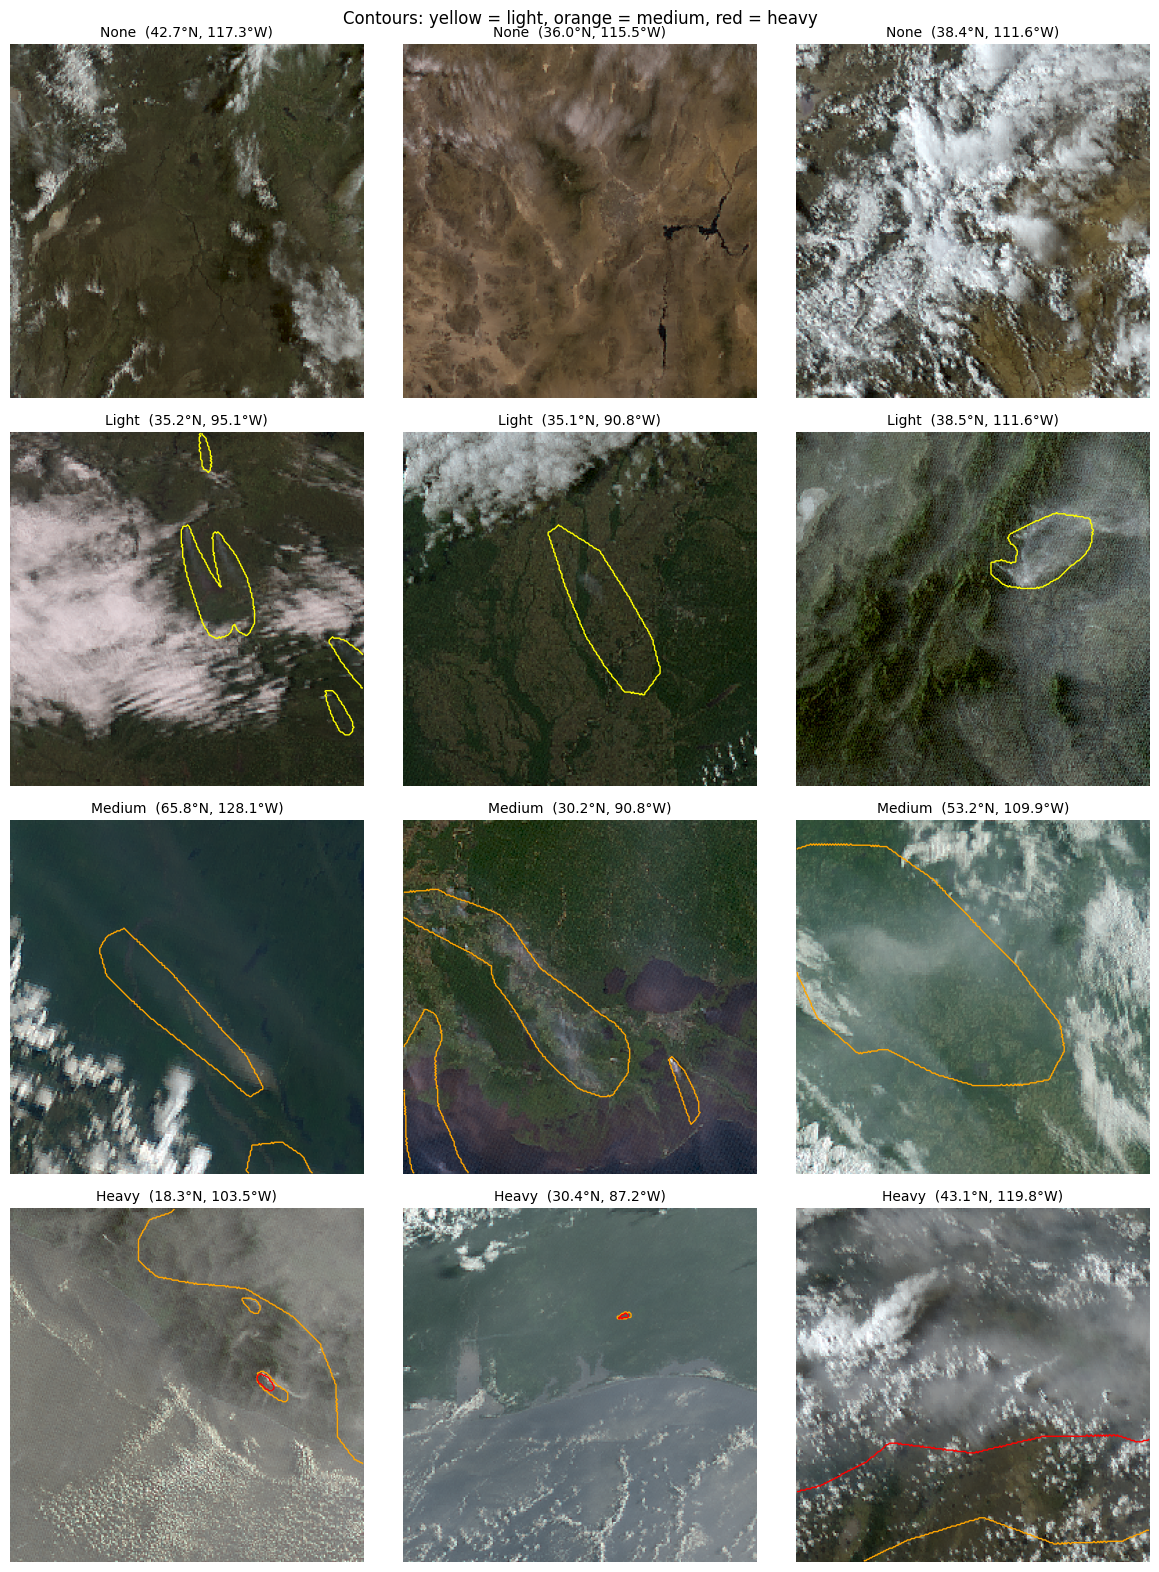

In [6]:
YEAR, N = "2023", 3
random.seed(0)
COLORS = ["yellow", "orange", "red"]   # contour of light, medium, heavy

fig, axes = plt.subplots(len(FOLDERS), N, figsize=(4 * N, 4 * len(FOLDERS)))
for r, fol in enumerate(FOLDERS):
    names = tiles.query("year == @YEAR and folder == @fol and mask != 'missing on S3'")["name"]
    for c, name in enumerate(random.sample(list(names), N)):
        ax = axes[r, c]
        ax.imshow(np.clip(tifffile.imread(ROOT / "data" / YEAR / fol / name), 0, 1))
        mask_path = ROOT / "truth" / YEAR / fol / name
        if mask_path.exists():
            mask = tifffile.imread(mask_path)
            for ch, col in zip([2, 1, 0], COLORS):
                if mask[..., ch].any():
                    ax.contour(mask[..., ch], levels=[0.5], colors=col, linewidths=1)
        lat, lon = tifffile.imread(ROOT / "coords" / YEAR / fol / name)[128, 128]
        ax.set_title(f"{fol}  ({lat:.1f}°N, {abs(lon):.1f}°W)", fontsize=10)
        ax.axis("off")
plt.suptitle("Contours: yellow = light, orange = medium, red = heavy")
plt.tight_layout()
plt.show()

## 5. Zenodo vs S3 consistency

For the tiles without a mask, check whether the image is on S3 or the mask is under another folder. For a few tiles with a mask, check that the Zenodo image is identical to the S3 one.

In [7]:
missing = tiles[tiles["mask"] == "missing on S3"]
print("Missing masks by year/folder:", missing.groupby(["year", "folder"], observed=True).size().to_dict())

for _, t in missing.head(5).iterrows():
    in_data = s3_exists(f"{S3_PREFIX}/data/{t.year}/{t.folder}/{t['name']}")
    other = [f for f in FOLDERS[1:]
             if f != t.folder and s3_exists(f"{S3_PREFIX}/truth/{t.year}/{f}/{t['name']}")]
    print(f"{t['name']} [{t.folder}] | image on S3: {in_data} | mask under other folder: {other}")

for _, t in tiles[tiles["mask"] == "from S3"].sample(5, random_state=0).iterrows():
    tmp = f"/tmp/{t['name']}"
    s3.download_file(BUCKET, f"{S3_PREFIX}/data/{t.year}/{t.folder}/{t['name']}", tmp)
    a = tifffile.imread(ROOT / "data" / t.year / t.folder / t["name"])
    b = tifffile.imread(tmp)
    print(t["name"], "| identical to S3:", a.shape == b.shape and np.allclose(a, b, equal_nan=True))

Missing masks by year/folder: {('2022', 'Light'): 38, ('2022', 'Medium'): 21, ('2022', 'Heavy'): 13}
G16_s20221050000205_e20221050009513_89.tif [Heavy] | image on S3: False | mask under other folder: []
G16_s20221882350217_e20221882359525_32.tif [Heavy] | image on S3: False | mask under other folder: []
G16_s20222762200203_e20222762209511_23.tif [Heavy] | image on S3: False | mask under other folder: []
G16_s20222862220206_e20222862229514_185.tif [Heavy] | image on S3: False | mask under other folder: []
G16_s20222922320204_e20222922329512_89.tif [Heavy] | image on S3: False | mask under other folder: []
G16_s20200852300214_e20200852309522_293.tif | identical to S3: True
G17_s20222861530321_e20222861539387_123.tif | identical to S3: False
G16_s20200962050203_e20200962059511_93.tif | identical to S3: True
G17_s20201611650321_e20201611659388_10.tif | identical to S3: True
G16_s20202262040200_e20202262049508_36.tif | identical to S3: True


## 6. Rebuilding val / test from 2022 on S3

With only 38 smoke tiles left in val / test (and no Heavy in val), per-class metrics would be meaningless. 2022 is kept as the held-out year, but its smoke tiles are taken from S3, where image and mask come from the same version.

First we list what S3 has for 2022 and check how the authors split val / test: the original split mostly follows alternating 10-day blocks but not strictly, so we use our own strict rule.

In [8]:
# 1. All 2022 masks on S3, by folder
keys = []
for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=f"{S3_PREFIX}/truth/2022/"):
    keys += [o["Key"] for o in page.get("Contents", [])]
print("Masks 2022 on S3:", len(keys), dict(collections.Counter(k.split("/")[3] for k in keys)))

# 2. Does S3 have smoke-free (None) tiles too?
resp = s3.list_objects_v2(Bucket=BUCKET, Prefix=f"{S3_PREFIX}/data/2022/", Delimiter="/")
print("Folders in data/2022:", [p["Prefix"] for p in resp.get("CommonPrefixes", [])])

# 3. How did the authors split val / test? (10-day block: even or odd)
block = lambda name: (int(re.search(r"_s\d{4}(\d{3})", name).group(1)) - 1) // 10
for split in ["val", "test"]:
    print(split, "block parity:", dict(collections.Counter(block(Path(p).name) % 2 for p in meta[split]["data"])))

Masks 2022 on S3: 15809 {'Heavy': 2155, 'Light': 9173, 'Medium': 4481}
Folders in data/2022: ['SmokeViz/data/2022/Heavy/', 'SmokeViz/data/2022/Light/', 'SmokeViz/data/2022/Medium/']
val block parity: {0: 83, 1: 16}
test block parity: {1: 84, 0: 15}


Then we sample the new smoke tiles, download them and save the final `splits.csv` (train from `subsample.pkl`; val / test = S3 smoke tiles + Zenodo 2022 `None` tiles). The download is restored from Drive on later runs.

In [9]:
N_PER_SPLIT = {"Light": 60, "Medium": 50, "Heavy": 40}   # smoke tiles per split, by folder
SEED = 42
S3_ROOT = Path("/content/smokeviz/s3_2022")              # new tiles: data/ + truth/ from S3
ZIP_S3 = f"{DRIVE_DIR}/s3_2022.zip"
SPLITS_CSV = f"{DRIVE_DIR}/splits.csv"

# val / test = alternating 10-day blocks of 2022 (even blocks -> val, odd -> test)
doy = lambda name: int(re.search(r"_s\d{4}(\d{3})", name).group(1))
split_of_day = lambda name: "val" if ((doy(name) - 1) // 10) % 2 == 0 else "test"

# 1. Candidate 2022 smoke tiles on S3 (`keys` comes from the previous cell)
cand = pd.DataFrame([k.split("/")[2:] for k in keys], columns=["year", "folder", "name"])
cand["split"] = cand["name"].map(split_of_day)
cand["scan"] = cand["name"].str.rsplit("_", n=1).str[0]   # tiles cut from the same satellite image

# 2. Random sample per split and folder, at most one tile per satellite image
shuffled = cand.sample(frac=1, random_state=SEED).drop_duplicates(["split", "folder", "scan"])
picked = pd.concat([g.head(N_PER_SPLIT[folder]) for (split, folder), g in shuffled.groupby(["split", "folder"])])

# 3. Download images + masks (restored from Drive if already downloaded once)
if os.path.exists(ZIP_S3):
    !unzip -q -o "{ZIP_S3}" -d /content/smokeviz


def fetch_tile(t):
    for kind in ["data", "truth"]:
        out = S3_ROOT / kind / t.year / t.folder / t.name
        if not out.exists():
            out.parent.mkdir(parents=True, exist_ok=True)
            s3.download_file(BUCKET, f"{S3_PREFIX}/{kind}/{t.year}/{t.folder}/{t.name}", str(out))


with ThreadPoolExecutor(32) as ex:
    list(ex.map(fetch_tile, picked.itertuples(index=False)))
if not os.path.exists(ZIP_S3):
    !cd /content/smokeviz && zip -qr "{ZIP_S3}" s3_2022

# 4. Final splits: train from the Zenodo pkl, val / test = new S3 smoke tiles + Zenodo 2022 None tiles
cols = ["split", "source", "root", "year", "folder", "name"]
train = tiles[tiles.split == "train"].assign(source="zenodo", root=str(ROOT))
none22 = tiles[(tiles.year == "2022") & (tiles.folder == "None")].assign(source="zenodo", root=str(ROOT))
none22["split"] = none22["name"].map(split_of_day)
new = picked.assign(source="s3", root=str(S3_ROOT))
splits = pd.concat([d.astype({"split": str, "folder": str})[cols] for d in [train, none22, new]], ignore_index=True)
splits.to_csv(SPLITS_CSV, index=False)

splits["split"] = pd.Categorical(splits.split, ["train", "val", "test"])
splits["folder"] = pd.Categorical(splits.folder, FOLDERS)
table = pd.crosstab(splits.split, splits.folder, margins=True, margins_name="Total")
table.index.name, table.columns.name = "Split", "Folder"
display(table.style.set_caption(f"Final splits (saved to {SPLITS_CSV})"))

Folder,None,Light,Medium,Heavy,Total
Split,,,,,
train,492,319,120,69,1000
val,51,60,50,40,201
test,37,60,50,40,187
Total,580,439,220,149,1388


## 7. Checks on the final splits

Reads `splits.csv` back from Drive and checks that val and test share no day, that every file exists, and that the training images (from Zenodo) are identical to the S3 version their masks come from.

In [10]:
s = pd.read_csv(SPLITS_CSV, dtype=str, keep_default_na=False)
print("Tiles per split:", s.split.value_counts().reindex(["train", "val", "test"]).to_dict())

v, t = s[s.split == "val"], s[s.split == "test"]
print("Shared days val/test:", sorted(set(v["name"].map(doy)) & set(t["name"].map(doy))))
print("None tiles moved from the original split:",
      sum(split_of.get((r.year, r.folder, r.name)) != r.split for r in s[s.folder == "None"].itertuples()))

missing_files = [r.name for r in s.itertuples()
                 if not (Path(r.root) / "data" / r.year / r.folder / r.name).exists()
                 or (r.folder != "None" and not (Path(r.root) / "truth" / r.year / r.folder / r.name).exists())]
print("Missing files:", len(missing_files))

Tiles per split: {'train': 1000, 'val': 201, 'test': 187}
Shared days val/test: []
None tiles moved from the original split: 16
Missing files: 0


In [11]:
# Training smoke images (Zenodo) vs the S3 version of the same file
train_smoke = s[(s.split == "train") & (s.folder != "None")]


def same_as_s3(t):
    tmp = f"/tmp/cmp_{t.year}_{t.folder}_{t.name}"
    s3.download_file(BUCKET, f"{S3_PREFIX}/data/{t.year}/{t.folder}/{t.name}", tmp)
    a, b = tifffile.imread(Path(t.root) / "data" / t.year / t.folder / t.name), tifffile.imread(tmp)
    os.remove(tmp)
    return a.shape == b.shape and np.allclose(a, b, equal_nan=True)


with ThreadPoolExecutor(32) as ex:
    same = list(ex.map(same_as_s3, train_smoke.itertuples(index=False)))
print(f"Train smoke tiles identical to S3: {sum(same)} / {len(same)}")

Train smoke tiles identical to S3: 508 / 508
